<p align="center">
  <span style="color:Navy; font-size:200%; font-weight:bold; vertical-align:middle;">
    Temas Selectos: Python para Ciencias de la Tierra
  </span>
</p>

# <font color="purple"> **Análisis espacial: Técnicas de análisis vectorial**</font>
---

# **<font color="ForestGreen"> Coordinate Reference System (CRS) </font>**

## **<font color="SeaGreen"> Coordenadas geográficas </font>**

> Definimos una posición en el planeata en grados de latitud y longitud, relativos al ecuador y al primer meridiano. Con este sistema podemos especificar cualquier ubicación en el planeta.


<div class="alert alert-block alert-info">
<b>Nota:</b> Cuidado, en python se usa el orden (longitud, latitud). Además la longitud está en un rango de -180 a 180 grados, y la latitud en un rango de 90 a -90 grados.
</div>

## **<font color="SeaGreen"> Coordenadas proyectadas </font>**
> Usualmente proyectamos el planeata en 2D para poder expresar ubicaciones en cooredenadas cartesianas x y y. 

Para minimizar el error de la proyección, existen distintas proyecciones: 
- Proyección de área iguales de Albert
- La proyección Mercator


Una representación es la `proj4` string, en python es representada como un diccionario. 
Por ejemplo: 

`proj = lonlat +datum=WGS84 +nodefs`

`{'proj': 'latlon','datum':'WGS84','no_defs':True}`


La mayoría de los datos están representados en el sistema EPSG
`+EPSG:4326` = WGS84 CRS geográfico (longitud,latitud)

En GeoPandas, la información del CRS se guarda en el atributo `crs`, lo que regresa es la proyección en un string o diccionario.

`geo_df = geopandas.read_file("archivo.shp")`

`print(geo_df.crs)`
imprime

`{'init':'epsg:4326'}`



In [2]:
#!pip install contextily
#!pip install mapclassify
#!pip install folium
#!pip install fiona

  Using cached contextily-1.7.1-py3-none-any.whl.metadata (3.1 kB)
  Using cached geopy-2.5.0-py3-none-any.whl.metadata (7.1 kB)
  Using cached mercantile-1.2.1-py3-none-any.whl.metadata (4.8 kB)
  Using cached xyzservices-2026.9.1-py3-none-any.whl.metadata (4.1 kB)
  Using cached geographiclib-2.1-py3-none-any.whl.metadata (1.6 kB)
Using cached contextily-1.7.1-py3-none-any.whl (18 kB)
Using cached geopy-2.5.0-py3-none-any.whl (114 kB)
Using cached mercantile-1.2.1-py3-none-any.whl (14 kB)
Using cached xyzservices-2026.9.1-py3-none-any.whl (98 kB)
Using cached geographiclib-2.1-py3-none-any.whl (40 kB)
  Using cached mapclassify-2.10.0-py3-none-any.whl.metadata (3.1 kB)
Using cached mapclassify-2.10.0-py3-none-any.whl (882 kB)
  Using cached folium-0.20.0-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
Using cached folium-0.20.0-py2.py3-none-any.whl (113 kB)
Using cached branca-0.8.2-py3-none-any.whl (26 kB)
  Using cached fiona-1.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
import contextily
import geopandas as gpd

from shapely.geometry import Point
import mapclassify

In [3]:
# Importen el archivo paris_districts_utm.geojson
districts = gpd.read_file("/home/jovyan/Clase_20271/data/paris_districts_utm.geojson")

# Impriman la información del CRS
print(districts.crs)
districts.crs

EPSG:32631


<Projected CRS: EPSG:32631>
Name: WGS 84 / UTM zone 31N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 0°E and 6°E, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Andorra. Belgium. Benin. Burkina Faso. Denmark - North Sea. France. Germany - North Sea. Ghana. Luxembourg. Mali. Netherlands. Niger. Nigeria. Norway. Spain. Togo. United Kingdom (UK) - North Sea.
- bounds: (0.0, 0.0, 6.0, 84.0)
Coordinate Operation:
- name: UTM zone 31N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Si no hay información sobre el tipo de CRS, se puede poner manualmante con el método `to_crs`.
Por ejemplo: 

`geo_df2 = geo_df.to_crs({'proj':'lonlat','datum':'WGS84','no_defs':True})` 

o 

`geo_df2 = geo_df.to_crs(epsg=4326)`

Recuerden que pueden usar el CRS de otro GeoDataFrame para llevar sus datos al mismo CRS

`geo_df2 = geo_df2.to_crs(geo_df1.crs)`


Recuerden que la elección del CRS depende del objetivo de su análisis. Sitios de interés:
- https://spatialreference.org/
- https://epsg.io/


In [4]:
# Vamos a crear el GeoDataFrame districts_lonlat usando el EPSG 4326
districts_lonlat = districts.to_crs("EPSG:4326")

#impriman el CRS
districts_lonlat.crs


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Vamos a ver la diferencia entre tres proyecciones:

1. Impriman el CRS de districts, y districts_lonlat
2. Muestren un mapa de districts
3. Conviertan districts a otra proyección CRS (EPSG:2154), este nuevo dataset se llamará districts_RGF93.
4. Creen un mapa para districts_RGF93.
5. Creen un mapa para districts_lonlat.

¿Ven alguna diferencia?


EPSG:32631


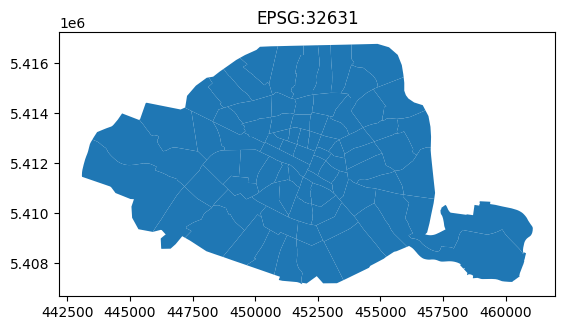

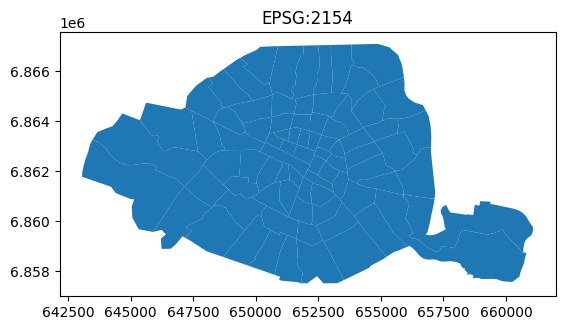

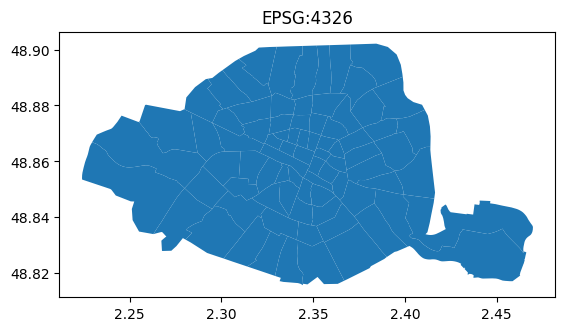

In [5]:
# Impriman el CRS de districts
print(districts.crs)

# Muestren el mapa
districts.plot();
plt.title(f"{districts.crs}")
plt.show()

# Conviertan districts al CRS RGF93
districts_RGF93 = districts.to_crs(epsg="2154");

# Muestren el mapa de districts_RGF93
districts_RGF93.plot();
plt.title(f"{districts_RGF93.crs}");
plt.show()

# Muestren el mapa de districts_lonlat
districts_lonlat.plot();
plt.title(f"{districts_lonlat.crs}");

## **<font color="SeaGreen"> Proyectando un punto. </font>**

En el notebook anterior, trabajamos con la ubicación de la Torre Eiffel. Nuevamente, proporcionamos las coordenadas en un sistema de coordenadas proyectadas para que, por ejemplo, se puedan calcular distancias. Volvamos a este emblemático monumento y expresemos su ubicación en coordenadas geográficas: 48°51′29.6″N, 2°17′40.2″E. En decimales: latitud 48.8584 y longitud 2.2945.

Los objetos geométricos Shapely no tienen noción de CRS y, por lo tanto, no se pueden convertir directamente a otro CRS. Por lo tanto, usaremos GeoPandas para transformar la ubicación del punto de la Torre Eiffel en un CRS alternativo. Introduciremos el punto en una GeoSeries, usaremos el método `to_crs()` y extraeremos el punto de nuevo.


* Creen un objeto POINT en shapely con las coordenadas de la Torre Eiffel y asígnelo a una variable llamada eiffel_tower.
* Creen una GeoSeries (llamada s_eiffel_tower) con la Torre Eiffel como único elemento y especifique el CRS EPSG:4326.
* Conviertan s_eiffel_tower a EPSG:2154 y llamen al resultado s_eiffel_tower_projected.


In [6]:
# Construyan un punto para la Torre Eiffel
eiffel_tower = Point(2.2945,48.8584)

# Conviertan el punto en una GeoSeries con el CRS correcto
s_eiffel_tower = gpd.GeoSeries([eiffel_tower], crs='EPSG:4326')

# Conviertan el punto a un CRS EPSG 2154
s_eiffel_tower_projected = s_eiffel_tower.to_crs(epsg="2154")

# Impriman el punto
print(s_eiffel_tower_projected)

0    POINT (648237.302 6862271.682)
dtype: geometry


## **<font color="SeaGreen"> Cálculo de la distancia en un sistema de coordenadas proyectado </font>**



Ahora que tenemos la ubicación de la Torre Eiffel en un sistema de coordenadas proyectado, podemos calcular la distancia a otros puntos.

Usaremos el último objeto `s_eiffel_tower_projected` del ejercicio anterior, que contiene el punto proyectado, y extraemos el punto único en la variable `eiffel_tower`. Además, también usaremos el dataframe de restaurantes (utilizando coordenadas WGS84).

1. Sube el archivo "paris_restaurants.csv" y conviértelo a un GeoDataFrame.
2. Convierte el GeoDataFrame al mismo CRS que el punto de la Torre Eiffel. Para este ejercicio, no especifiques la palabra clave epsg, sino el atributo .crs.
3. Calcula la distancia de todos los restaurantes a la Torre Eiffel.
4. Imprime la distancia más pequeña.

In [7]:
# Leemos el archivo csv
df =pd.read_csv("/home/jovyan/Clase_20271/data/paris_restaurants.csv")

# Convertir df a un GeoDataFrame
restaurants = gpd.GeoDataFrame( df, geometry=gpd.points_from_xy(df['x'], df['y']), crs="EPSG:32633")  ; 

In [8]:
restaurants.crs

<Projected CRS: EPSG:32633>
Name: WGS 84 / UTM zone 33N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 12°E and 18°E, northern hemisphere between equator and 84°N, onshore and offshore. Austria. Bosnia and Herzegovina. Cameroon. Central African Republic. Chad. Congo. Croatia. Czechia. Democratic Republic of the Congo (Zaire). Gabon. Germany. Hungary. Italy. Libya. Malta. Niger. Nigeria. Norway. Poland. San Marino. Slovakia. Slovenia. Svalbard. Sweden. Vatican City State.
- bounds: (12.0, 0.0, 18.0, 84.0)
Coordinate Operation:
- name: UTM zone 33N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [9]:
#Conviertan el CRS del punto s_eiffel_tower al mismo que restaurants 
s_eiffel_tower_projected = s_eiffel_tower.to_crs(restaurants.crs)
eiffel_tower = s_eiffel_tower_projected.iloc[0]

In [10]:
s_eiffel_tower_projected.crs

<Projected CRS: EPSG:32633>
Name: WGS 84 / UTM zone 33N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 12°E and 18°E, northern hemisphere between equator and 84°N, onshore and offshore. Austria. Bosnia and Herzegovina. Cameroon. Central African Republic. Chad. Congo. Croatia. Czechia. Democratic Republic of the Congo (Zaire). Gabon. Germany. Hungary. Italy. Libya. Malta. Niger. Nigeria. Norway. Poland. San Marino. Slovakia. Slovenia. Svalbard. Sweden. Vatican City State.
- bounds: (12.0, 0.0, 18.0, 84.0)
Coordinate Operation:
- name: UTM zone 33N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [11]:
#Calculen la distancia de cada restaurante al torre Eiffel
dist_eiffel = restaurants.distance(eiffel_tower)

#Impriman las distancias

dist_eiffel

0       1.028192e+06
1       1.028266e+06
2       1.028407e+06
3       1.028470e+06
4       1.028431e+06
            ...     
5730    1.029290e+06
5731    1.029345e+06
5732    1.033034e+06
5733    1.033040e+06
5734    1.032425e+06
Length: 5735, dtype: float64

In [12]:
# Impriman la distancia mínima
dist_eiffel.min()

np.float64(1019296.5666782534)

### **<font color="SeaGreen"> Operaciones espaciales: creación de nuevas geometrías </font>**

De manera similar a la clase pasada, podemos hacer ciertas operaciones con polígonos, por ejemplo:


**1. Obtener intersecciones de polígonos**

**2. Obtener uniones**
**3. Obtener diferencias**

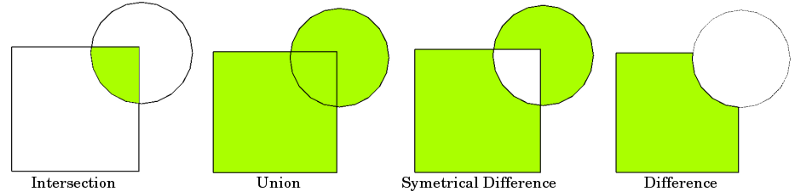

### **<font color="SeaGreen"> Datos de uso del suelo </font>**

Para los siguientes ejercicios, primero presentamos un nuevo conjunto de datos: un conjunto de datos sobre el uso del suelo de París. El uso del suelo indica para qué tipo de actividad se utiliza una zona determinada, como residencial o recreativa. Se trata de un conjunto de datos multipoligonal, con una etiqueta que representa la clase de uso del suelo para las diferentes zonas de París.

En este ejercicio, leeremos los datos, los exploraremos visualmente y calcularemos la superficie total de las diferentes clases de uso del suelo en la zona de París.

Esta base de datos viene de: https://land.copernicus.eu/en/products/urban-atlas

* Lea el archivo 'FR001L1_PARIS_UA2012_revised_v021.gpkg' y asigne el resultado a la variable land_use.
* Genere un gráfico de land_use, usando la columna 'class_2012' para colorear los polígonos. También agregamos una leyenda. 
>Nota: El gráfico puede tardar unos segundos en generarse debido a la gran cantidad de polígonos.

* Agregue una nueva columna 'area' con el área de cada polígono.
* Calcule el área total en km² para cada 'class_2012' usando el método groupby() e imprima el resultado.

In [13]:
#pip install gdown

In [14]:
from pathlib import Path
import gdown
import zipfile

In [15]:
from pathlib import Path
import gdown
import zipfile

# Enlace de la carpeta de Google Drive
url = "https://drive.google.com/drive/folders/1FVidvADCUYQMbhWMCcZUCQdizibBVEf7"

# Carpeta de destino en JupyterHub
destino = Path("/home/jovyan/Clase_20271/data") #Dónde quieren guardar sus datos
destino.mkdir(parents=True, exist_ok=True)

# Descargar el contenido de la carpeta de Drive
resultado = gdown.download_folder(url,output=str(destino / "descargas"),quiet=False,use_cookies=False)

if resultado:
    # Buscar y extraer todos los ZIP descargados
    for archivo_zip in (destino / "descargas").rglob("*.zip"):
        carpeta_extraida = destino / archivo_zip.stem
        carpeta_extraida.mkdir(parents=True, exist_ok=True)

        print(f"Descomprimiendo: {archivo_zip.name}")

        with zipfile.ZipFile(archivo_zip, "r") as z:
            z.extractall(carpeta_extraida)

        print(f"Extraído en: {carpeta_extraida}")

    print("Proceso terminado.")
else:
    print("No se pudo descargar la carpeta de Drive.")
    print("Verifica los permisos y que el enlace sea accesible.")

Retrieving folder contents


Processing file 1lIuRqxqgFdWO2izEUmGsZXEY7YlqTmsO FR001L1_PARIS_UA2012_revised_v021.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1lIuRqxqgFdWO2izEUmGsZXEY7YlqTmsO
From (redirected): https://drive.google.com/uc?id=1lIuRqxqgFdWO2izEUmGsZXEY7YlqTmsO&confirm=t&uuid=9578c37f-281c-4973-9573-8ed8aa2d4dc7
To: /home/jovyan/Clase_20271/data/descargas/FR001L1_PARIS_UA2012_revised_v021.zip
100%|██████████| 287M/287M [00:04<00:00, 62.7MB/s] 
Download completed


Descomprimiendo: FR001L1_PARIS_UA2012_revised_v021.zip
Extraído en: /home/jovyan/Clase_20271/data/FR001L1_PARIS_UA2012_revised_v021
Descomprimiendo: colorado-flood.zip
Extraído en: /home/jovyan/Clase_20271/data/colorado-flood
Proceso terminado.


In [16]:
import fiona
# Antes de abrir su archivo, tienen que saber que a veces las bases de datos vienen en capas, 
# para ver las capa que contiene nuestra base podemos usar la siguiente librería y función

layers = fiona.listlayers('/home/jovyan/Clase_20271/data/FR001L1_PARIS_UA2012_revised_v021/FR001L1_PARIS_UA2012_revised_v021.gpkg')
print(layers)


['FR001L1_PARIS_UA2012_revised', 'FR001L1_PARIS_UA2012_revised_Boundary', 'FR001L1_PARIS_UA2012_revised_UrbanCore']


In [17]:
# Para leer la capa principal
land_use = gpd.read_file('/home/jovyan/Clase_20271/data/FR001L1_PARIS_UA2012_revised_v021/FR001L1_PARIS_UA2012_revised_v021.gpkg', layer='FR001L1_PARIS_UA2012_revised')

# Para leer la capa de límites
boundary = gpd.read_file('/home/jovyan/Clase_20271/data/FR001L1_PARIS_UA2012_revised_v021/FR001L1_PARIS_UA2012_revised_v021.gpkg', layer='FR001L1_PARIS_UA2012_revised_Boundary')

# Para leer la capa del núcleo urbano
urban_core = gpd.read_file('/home/jovyan/Clase_20271/data/FR001L1_PARIS_UA2012_revised_v021/FR001L1_PARIS_UA2012_revised_v021.gpkg', layer='FR001L1_PARIS_UA2012_revised_UrbanCore')

In [18]:
np.unique(land_use["class_2012"])

array(['Airports', 'Arable land (annual crops)',
       'Complex and mixed cultivation patterns', 'Construction sites',
       'Continuous urban fabric (S.L. : > 80%)',
       'Discontinuous dense urban fabric (S.L. : 50% -  80%)',
       'Discontinuous low density urban fabric (S.L. : 10% - 30%)',
       'Discontinuous medium density urban fabric (S.L. : 30% - 50%)',
       'Discontinuous very low density urban fabric (S.L. : < 10%)',
       'Fast transit roads and associated land', 'Forests',
       'Green urban areas',
       'Herbaceous vegetation associations (natural grassland, moors...)',
       'Industrial, commercial, public, military and private units',
       'Isolated structures', 'Land without current use',
       'Mineral extraction and dump sites',
       'Open spaces with little or no vegetation (beaches, dunes, bare rocks, glaciers)',
       'Other roads and associated land', 'Pastures',
       'Permanent crops (vineyards, fruit trees, olive groves)',
       'Port area

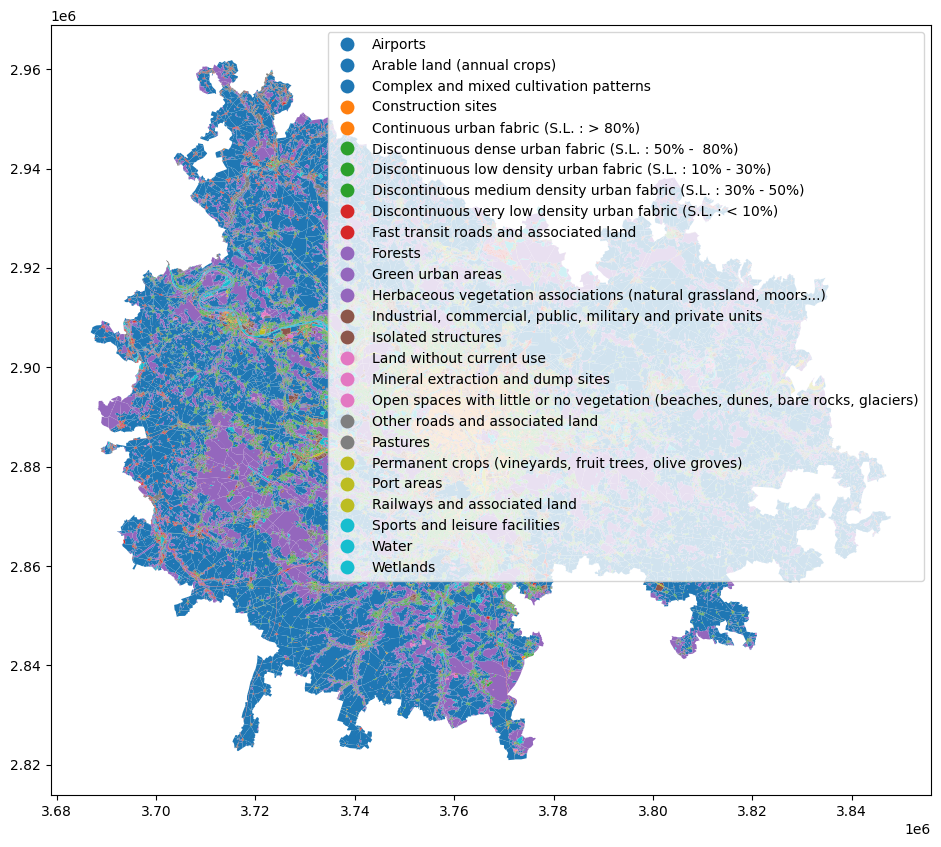

In [19]:
#Creen un mapa para land_use de modo se coloree considerando el tipo de uso de suelo ('class_2012')
land_use.plot(column = 'class_2012', legend=True, legend_kwds={'loc': 'upper right'},figsize=(15, 10))
plt.show()


In [20]:
#Creen otra columna donde midan el área de cada geometría
land_use['area'] = land_use.geometry.area

In [21]:
land_use

,country,fua_name,fua_code,code_2012,class_2012,prod_date,identifier,perimeter,area,comment,Pop2012,geometry
0,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,59856-FR001L1,3239.214688,69512.517102,None,245,"MULTIPOLYGON (((3766403.313 2865861.102, 37664..."
1,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,35716-FR001L1,3683.301943,85542.006098,None,582,"MULTIPOLYGON (((3737000 2881423.178, 3737133.2..."
2,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,63106-FR001L1,1947.727258,46238.905137,None,269,"MULTIPOLYGON (((3738341.211 2882811.812, 37383..."
3,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,50109-FR001L1,2896.906914,61729.358691,None,505,"MULTIPOLYGON (((3725829.731 2904000, 3725829.5..."
4,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,34769-FR001L1,3492.680561,76894.419482,None,543,"MULTIPOLYGON (((3779087.644 2879410.388, 37790..."
...,...,...,...,...,...,...,...,...,...,...,...,...
156045,FR,Paris,FR001L1,11100,Continuous urban fabric (S.L. : > 80%),2020-09,188603-FR001L1,240.746078,3284.410140,None,0,"MULTIPOLYGON (((3759389.779 2893047.395, 37594..."
156046,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188612-FR001L1,411.802336,9339.031431,None,0,"MULTIPOLYGON (((3754993.027 2907163.541, 37549..."
156047,FR,Paris,FR001L1,11230,Discontinuous low density urban fabric (S.L. :...,2020-09,188589-FR001L1,536.345476,11463.881858,None,0,"MULTIPOLYGON (((3758064.68 2843135.239, 375807..."
156048,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188588-FR001L1,337.539251,5285.394648,None,0,"MULTIPOLYGON (((3769571.74 2883702.77, 3769571..."


In [22]:
# Agrupen land_use considerando el tipo de uso y calculen el área de cada clase en km2.
total_area = land_use.groupby('class_2012')['area'].sum() / 1000**2
total_area

class_2012
Airports                                                                             69.973548
Arable land (annual crops)                                                         6182.848221
Complex and mixed cultivation patterns                                                0.781338
Construction sites                                                                   14.522172
Continuous urban fabric (S.L. : > 80%)                                              222.131187
Discontinuous dense urban fabric (S.L. : 50% -  80%)                                531.758994
Discontinuous low density urban fabric (S.L. : 10% - 30%)                           150.068569
Discontinuous medium density urban fabric (S.L. : 30% - 50%)                        311.633005
Discontinuous very low density urban fabric (S.L. : < 10%)                          131.002326
Fast transit roads and associated land                                               34.476144
Forests                                

### **<font color="SeaGreen"> Intersección de dos polígonos </font>**


Para este ejercicio, utilizaremos dos polígonos individuales: el distrito de Muette, que extraeremos del conjunto de datos `"districts"`, y un parque público al oeste de París, que extraeremos del conjunto de datos `"land_use"`.



In [23]:
districts

,id,district_name,population,geometry
0,1,St-Germain-l'Auxerrois,1672,"POLYGON ((451922.133 5411438.484, 451922.08 54..."
1,2,Halles,8984,"POLYGON ((452278.419 5412160.893, 452192.407 5..."
2,3,Palais-Royal,3195,"POLYGON ((451553.806 5412340.522, 451528.058 5..."
3,4,Place-Vendôme,3044,"POLYGON ((451004.908 5412654.095, 450960.64 54..."
4,5,Gaillon,1345,"POLYGON ((451328.752 5412991.278, 451294.721 5..."
...,...,...,...,...
75,76,Combat,38988,"POLYGON ((455155.128 5414359.413, 455239.337 5..."
76,77,Belleville,35773,"POLYGON ((454767.853 5412865.188, 454761.185 5..."
77,78,Saint-Fargeau,42087,"POLYGON ((457014.145 5413260.154, 457015.161 5..."
78,79,Père-Lachaise,42332,"POLYGON ((455648.392 5411702.054, 455580.676 5..."


In [24]:
# Primero extrae el distrito 'Muette' de districts
muette =districts[districts["district_name"]=="Muette"]
muette

,id,district_name,population,geometry
61,62,Muette,45214,"POLYGON ((444686.86 5413985.234, 445358.893 54..."


In [25]:
land_use

,country,fua_name,fua_code,code_2012,class_2012,prod_date,identifier,perimeter,area,comment,Pop2012,geometry
0,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,59856-FR001L1,3239.214688,69512.517102,None,245,"MULTIPOLYGON (((3766403.313 2865861.102, 37664..."
1,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,35716-FR001L1,3683.301943,85542.006098,None,582,"MULTIPOLYGON (((3737000 2881423.178, 3737133.2..."
2,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,63106-FR001L1,1947.727258,46238.905137,None,269,"MULTIPOLYGON (((3738341.211 2882811.812, 37383..."
3,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,50109-FR001L1,2896.906914,61729.358691,None,505,"MULTIPOLYGON (((3725829.731 2904000, 3725829.5..."
4,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,34769-FR001L1,3492.680561,76894.419482,None,543,"MULTIPOLYGON (((3779087.644 2879410.388, 37790..."
...,...,...,...,...,...,...,...,...,...,...,...,...
156045,FR,Paris,FR001L1,11100,Continuous urban fabric (S.L. : > 80%),2020-09,188603-FR001L1,240.746078,3284.410140,None,0,"MULTIPOLYGON (((3759389.779 2893047.395, 37594..."
156046,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188612-FR001L1,411.802336,9339.031431,None,0,"MULTIPOLYGON (((3754993.027 2907163.541, 37549..."
156047,FR,Paris,FR001L1,11230,Discontinuous low density urban fabric (S.L. :...,2020-09,188589-FR001L1,536.345476,11463.881858,None,0,"MULTIPOLYGON (((3758064.68 2843135.239, 375807..."
156048,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188588-FR001L1,337.539251,5285.394648,None,0,"MULTIPOLYGON (((3769571.74 2883702.77, 3769571..."


In [26]:
# Ahora van a extraer las áreas verdes urbanas 'Green urban areas' de land_use 
green_areas = land_use[land_use["class_2012"]=="Green urban areas"]
green_areas

,country,fua_name,fua_code,code_2012,class_2012,prod_date,identifier,perimeter,area,comment,Pop2012,geometry
50,FR,Paris,FR001L1,14100,Green urban areas,2020-09,186527-FR001L1,8074.665528,335791.190107,None,0,"MULTIPOLYGON (((3766492.221 2880078.504, 37665..."
88,FR,Paris,FR001L1,14100,Green urban areas,2020-09,146519-FR001L1,379.729013,7783.092592,None,0,"MULTIPOLYGON (((3747541.108 2861625.653, 37475..."
774,FR,Paris,FR001L1,14100,Green urban areas,2020-09,146225-FR001L1,252.731367,3960.979838,None,0,"MULTIPOLYGON (((3763460.188 2855487.637, 37635..."
781,FR,Paris,FR001L1,14100,Green urban areas,2020-09,147450-FR001L1,318.119311,5543.429494,None,0,"MULTIPOLYGON (((3777498.492 2874922.164, 37774..."
800,FR,Paris,FR001L1,14100,Green urban areas,2020-09,149792-FR001L1,276.376876,3001.919960,None,0,"MULTIPOLYGON (((3766177.803 2894835.628, 37661..."
...,...,...,...,...,...,...,...,...,...,...,...,...
155537,FR,Paris,FR001L1,14100,Green urban areas,2020-09,188078-FR001L1,382.234573,5652.130605,None,0,"MULTIPOLYGON (((3735322.034 2889386.997, 37352..."
155538,FR,Paris,FR001L1,14100,Green urban areas,2020-09,188075-FR001L1,4951.377297,430547.897712,None,0,"MULTIPOLYGON (((3710403.111 2911170.309, 37103..."
155539,FR,Paris,FR001L1,14100,Green urban areas,2020-09,188076-FR001L1,2480.794346,155466.515557,None,0,"MULTIPOLYGON (((3743936.32 2911733.055, 374398..."
155541,FR,Paris,FR001L1,14100,Green urban areas,2020-09,188079-FR001L1,4199.777125,277744.896620,None,0,"MULTIPOLYGON (((3735301.005 2889365.513, 37353..."


In [27]:
# Si quisieran explorar todas las areas verdes de París, recuerden esta herramienta
green_areas.explore() 

In [28]:
# No queremos trabajar con todas las áreas, así que extraeremos un parque de green_areas
# Extraigan el dato cuyo identificador es '149138-FR001L1'
parque =green_areas[green_areas['identifier'] == '149138-FR001L1']
parque

,country,fua_name,fua_code,code_2012,class_2012,prod_date,identifier,perimeter,area,comment,Pop2012,geometry
5531,FR,Paris,FR001L1,14100,Green urban areas,2020-09,149138-FR001L1,510.522552,11357.733148,None,0,"MULTIPOLYGON (((3756307.149 2890342.264, 37562..."


In [29]:
## Antes de hacer cualquier cosa, debemos asegurarnos que ambos polígonos tengan el mismo crs
print(parque.crs)
print(muette.crs)

EPSG:3035
EPSG:32631


In [30]:
# Si no es el mismo, conviertan el crs de muette para que tenga el crs de parque
muette = muette.to_crs(parque.crs)

##### **Ya tenemos los dos sitios que queremos estudiar**

Ahora, vamos a:
* Trazar los dos polígonos en un solo mapa para examinar visualmente el grado de superposición.
* Calcular la intersección de los polígonos del parque y del distrito Muette.
* Carlular la proporción del área del distrito que ocupa el parque.

> NOTA: parque es un multipolígono y muette es un polígono, esto nos puede causar problemas para poder visualizarlo y hacer operaciones.
> Siempre deben verificar el tipo de geometrías que tienen sus objetos. 

In [31]:
muette.geometry

61    POLYGON ((3753224.021 2892487.772, 3753868.704...
Name: geometry, dtype: geometry

In [32]:
parque.geometry

5531    MULTIPOLYGON (((3756307.149 2890342.264, 37562...
Name: geometry, dtype: geometry

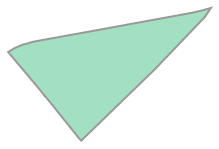

In [33]:
# Como parque es un multipolígono y muette un polígono, debemos llevar a parque a la misma geometría que muette.
parque_union = parque.union_all()
parque_union

In [34]:
# Si tenemos dudas de si hemos hecho algo mal en la extraccion de información, podemos usar esto
print(parque.geometry.is_empty.any())
print(muette.geometry.is_empty.any())

False
False


Ahora, visualicemos los dos polígonos.


Tenemos dos formas de hacerlo.

Verán que se superponen.



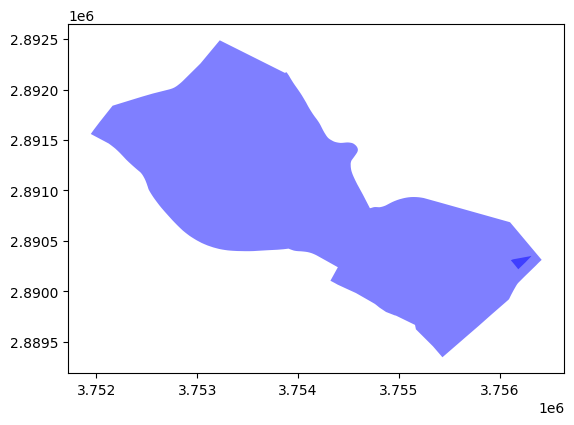

In [35]:
parque_geom = parque.geometry.iloc[0]
muette_geom = muette.geometry.iloc[0]

gpd.GeoSeries([parque_geom, muette_geom]).plot(alpha=0.5, color='blue')
plt.show()


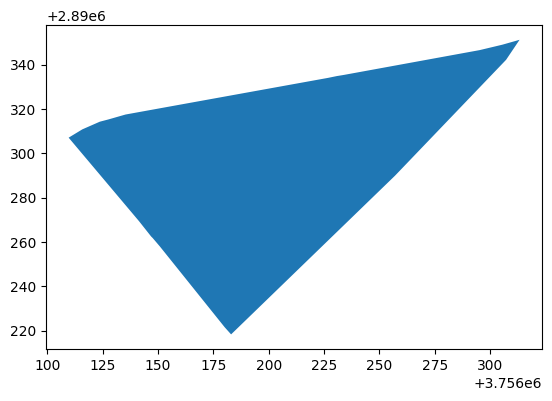

In [36]:
# Ahora, calcularemos la intersección de estos polígonos. 
# En este caso, tenemos que usar las geometrías 

intersection = parque_geom.intersection(muette_geom)

# Ahora, grafiquen la intersección 
gpd.GeoSeries(intersection).plot()
plt.show()


In [37]:
# Calculen la proporción del área del distrito que esta ocupada por el parque
print(intersection.area / muette_geom.area )

0.002072948768172278


Tal vez ahora no parezca de mucha utilidad calcular la intersección, pero si el parque estuviera en dos distritos diferentes, nos daría una idea de cuál distrito tiene más área de parque. 

Otra forma de ver el área que ocupa el parque es graficando la diferencia. 

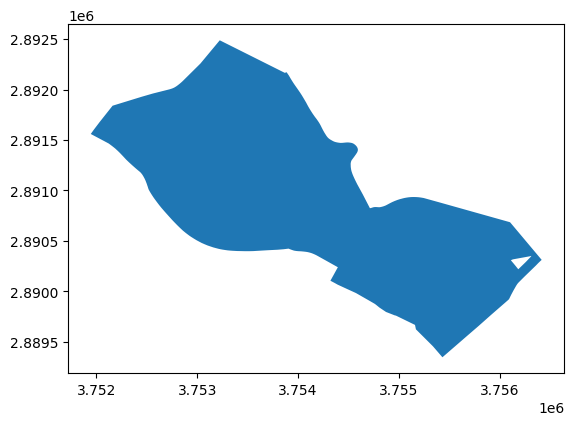

In [38]:
# Ahora, quiten el área del parque al distrito muette.
difer = muette_geom.difference(parque_geom)

# Ahora, grafiquen el resultado 
gpd.GeoSeries(difer).plot()
plt.show()



---
### **<font color="SeaGreen"> Intersección de un GeoDataFrame con un polígono </font>**

Al combinar los conjuntos de datos de uso del suelo y de distritos, podemos investigar el uso del suelo en un distrito determinado.

Para ello, primero debemos determinar la intersección de los conjuntos de datos de uso del suelo con un distrito determinado. Tomemos como ejemplo el distrito de Muette.

1. Calcula la intersección de los polígonos land_use con el polígono muette. Llama al resultado land_use_muette.
2. Gráfica rápidamente esta intersección y pasa edgecolor='black' para ver con mayor claridad los límites de los diferentes polígonos.
3. Imprime las primeras cinco filas de land_use_muette.



In [39]:
# Si quisieran explorar todas las áreas verdes de Paris, recuerden esta herramienta
#green_areas.explore() 

In [40]:
# Antes de hacer la intersección, debemos asegurarnos que ambos GeoDataFrames tengan el mismo CRS
#Imprime los CRS de cada GeoDataFrame
print(land_use.crs)
print(muette.crs)

EPSG:3035
EPSG:3035


In [41]:
land_use

,country,fua_name,fua_code,code_2012,class_2012,prod_date,identifier,perimeter,area,comment,Pop2012,geometry
0,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,59856-FR001L1,3239.214688,69512.517102,None,245,"MULTIPOLYGON (((3766403.313 2865861.102, 37664..."
1,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,35716-FR001L1,3683.301943,85542.006098,None,582,"MULTIPOLYGON (((3737000 2881423.178, 3737133.2..."
2,FR,Paris,FR001L1,11220,Discontinuous medium density urban fabric (S.L...,2020-09,63106-FR001L1,1947.727258,46238.905137,None,269,"MULTIPOLYGON (((3738341.211 2882811.812, 37383..."
3,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,50109-FR001L1,2896.906914,61729.358691,None,505,"MULTIPOLYGON (((3725829.731 2904000, 3725829.5..."
4,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,34769-FR001L1,3492.680561,76894.419482,None,543,"MULTIPOLYGON (((3779087.644 2879410.388, 37790..."
...,...,...,...,...,...,...,...,...,...,...,...,...
156045,FR,Paris,FR001L1,11100,Continuous urban fabric (S.L. : > 80%),2020-09,188603-FR001L1,240.746078,3284.410140,None,0,"MULTIPOLYGON (((3759389.779 2893047.395, 37594..."
156046,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188612-FR001L1,411.802336,9339.031431,None,0,"MULTIPOLYGON (((3754993.027 2907163.541, 37549..."
156047,FR,Paris,FR001L1,11230,Discontinuous low density urban fabric (S.L. :...,2020-09,188589-FR001L1,536.345476,11463.881858,None,0,"MULTIPOLYGON (((3758064.68 2843135.239, 375807..."
156048,FR,Paris,FR001L1,11210,Discontinuous dense urban fabric (S.L. : 50% -...,2020-09,188588-FR001L1,337.539251,5285.394648,None,0,"MULTIPOLYGON (((3769571.74 2883702.77, 3769571..."


In [ ]:
# Para hacer la intersección de los dos GeoDataFrames usaremos una nueva función de geopandas
# Esta nos permitirá crear un nuevo GeoDataFrame a partir de dos, pueden usar  ‘intersection’, ‘union’, ‘identity’, ‘symmetric_difference’ or ‘difference’.
# Recuerden que sjoin tambien puede ayudar
land_use_muette =  gpd.overlay(land_use, muette, how='intersection')

#impriman las primeras filas de land_use_muette
land_use_muette

In [ ]:
# Gráfica esta intersección y pasa edgecolor='black' para ver con mayor claridad los límites de los diferentes polígonos.
land_use_muette.plot(edgecolor='black' )

In [ ]:
# Gráfica esta intersección, ahora que se coloree por tipo de uso y pasa edgecolor='black' para ver con mayor claridad los límites de los diferentes polígonos.
land_use_muette.plot(column='class_2012', legend =True,edgecolor='black')

### **<font color="SeaGreen"> Minería en el congo </font>** 

En este ejercicio, comenzaremos leyendo y explorando dos nuevos conjuntos de datos:

Primero, un conjunto de datos sobre yacimientos de minería artesanal en el este del Congo (adaptado de los datos abiertos de IPIS).
https://ipisresearch.be/wp-content/uploads/2018/03/Open_Data_Tutorial.html
Segundo, un conjunto de datos sobre los parques nacionales del Congo (del Instituto de Recursos Mundiales).
https://cod-data.forest-atlas.org/

Para cada uno de estos conjuntos de datos, leen los datos con geopandas.read_file(), inspeccionen las primeras 5 filas y el Sistema de Referencia de Coordenadas (CRS) de los datos, y realicen una visualización rápida.

1. Extraigan los datos de Protected_areas.zip
2. Lean y exploren los datos del sitio minero ("ipis_cod_mines.geojson"), asignándolos a una variable llamada mining_sites.
3. Lean y exploren los datos de las área protegidas ("Protected_areas.shp") y asígnelo a national_parks

In [ ]:
zip_path = '/home/jovyan/Clase_20271/data/Protected_areas.zip'  # Cambia esto por la ruta real
extract_to = '/home/jovyan/Clase_20271/data'  # Carpeta donde se extraerán los archivos
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

In [ ]:
zip_path = '/home/jovyan/Clase_20271/data/Mines.zip'  # Cambia esto por la ruta real
extract_to = '/home/jovyan/Clase_20271/data'  # Carpeta donde se extraerán los archivos
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

In [ ]:
# Lean las bases de datos
mining_sites = gpd.read_file("/home/jovyan/Clase_20271/data/ipis_cod_mines.geojson")
national_parks = gpd.read_file("/home/jovyan/Clase_20271/data/Protected_areas.shp")


In [ ]:
# Impriman las primeras filas y el CRS de cada GeoDataFrame
print(mining_sites.head())
print(national_parks.crs)


In [ ]:
print(national_parks.head())
print(national_parks.crs)

In [ ]:
# Creen un mapa rápido.
fig, ax = plt.subplots()
mining_sites.plot(ax=ax,color="red")
national_parks.plot(ax=ax)
contextily.add_basemap(ax)
plt.show()

### **<font color="SeaGreen"> Convertir a un CRS común y guardarlo en un archivo </font>** 

Como vimos en los ejercicios anteriores, ambos conjuntos de datos utilizan un Sistema de Referencia de Coordenadas (CRS) diferente. Esto también se ilustra en los primeros gráficos. Ambos conjuntos de datos se refieren a la misma región, por lo que normalmente deberían superponerse en sus coordenadas; pero no es así.

Para realizar los análisis, convertiremos ambos conjuntos de datos al mismo CRS y los guardaremos en un nuevo archivo. Para garantizar que podamos realizar cálculos basados en la distancia, los convertiremos a un CRS proyectado: la zona UTM local 35, identificada por EPSG:32735 (https://epsg.io/32735).
Entonces:
1. Convierta ambos conjuntos de datos (mining_sites y national_parks) a EPSG:32735.Asigne a los resultados el nombre mining_sites_utm y national_parks_utm.
2. Intente visualizar de nuevo ambos conjuntos de datos en un solo mapa. ¿Se superponen ahora ambos conjuntos de datos?

In [ ]:
# Convertir ambos GeoDataFrames al mismo CRS 
mining_sites_utm = mining_sites.to_crs(epsg='32735')
national_parks_utm = national_parks.to_crs(epsg='32735')


In [ ]:
national_parks_utm.crs

In [ ]:
# Mostrar el mapa de los datos con la proyección 
ax = national_parks_utm.plot()
mining_sites_utm.plot(ax=ax, color='red')
plt.show()

## **Generar un archivo**

Escriba mining_sites_utm en un archivo GeoPackage llamado "ipis_cod_mines_utm.gpkg" y escriba national_parks_utm en un Shapefile ESRI llamado "cod_conservation_utm.shp".

Para esto, usamos la función .to_file("archivo_nuevo.tipo", driver="driver")

Para archivos .gpkg, driver='GPKG'
Para archivos .shp, driver='ESRI Shapefile'

In [ ]:
# Write converted data to a file
mining_sites_utm.to_file("ipis_cod_mines_utm.gpkg", driver='GPKG')

In [ ]:
national_parks_utm.to_file("cod_conservation_utm.shp", driver='ESRI Shapefile')

### **<font color="SeaGreen"> Diseño de un gráfico multicapa </font>**  

Ahora que hemos convertido ambos conjuntos de datos al mismo Sistema de Referencia de Coordenadas (CRS), vamos a crear un gráfico más atractivo combinando ambos.
Usando los datos convertidos, edite el código para trazar los parques nacionales como polígonos verdes y los sitios mineros como pequeños puntos (un tamaño de marcador de 5).

In [ ]:
# Mapa de los parque y sitios de minería
ax = national_parks_utm.plot(color='green')
mining_sites_utm.plot(ax=ax, markersize=0.5)
plt.show()

In [ ]:
# Mapa de los parque y sitios de minería ahora usando  alpha=0.5 para que los puntos de mining_site se grafiquen por tamaños
ax = ax = national_parks.plot(color='green')
mining_sites.plot(ax=ax, markersize=5, alpha=0.5)
ax.set_axis_off()
plt.show()

In [ ]:
#Mapa de los parque y sitios de minería ahora pidiendo que mining_sites se coloree por tipo de mineral 
ax = national_parks.plot(color='green')
mining_sites.plot(ax=ax, markersize=5, column = 'mineral', legend=True)
ax.set_axis_off()
#contextily.add_basemap(ax)
plt.show()

### **<font color="SeaGreen"> Buffers, Zona de influencia alrededor de un punto</font>**  


Considere la ciudad de Goma, capital de la provincia de Kivu del Norte del Congo, cerca de la frontera con Ruanda. Sus coordenadas son 1,66°S 29,22°E (el punto ya se proporciona en coordenadas UTM como la variable goma).

¿Cuántos yacimientos mineros se encuentran a menos de 50 km de Goma? ¿Y qué extensión tiene el parque nacional? Determinémoslo mediante la operación de zona de influencia. Recuerde que las distancias deben expresarse en la unidad del CRS (es decir, en metros en este caso).

Nota: Si tiene una serie booleana (por ejemplo, como resultado de un método de relación espacial), puede calcular cuántos valores verdaderos (es decir, cuántas geometrías pasaron la comprobación) sumando esos valores booleanos, ya que, en ese caso, los valores verdaderos y falsos se verán como unos y ceros.

* Crea una zona de influencia de 50 km alrededor de goma y asígnala a la variable goma_buffer.
* Comprueba cuáles de los puntos de mining_sites se encuentran dentro de esta zona de influencia (y llámala máscara). Cuenta esos sitios sumando la máscara booleana e imprime el resultado.
* Calcula las intersecciones de los parques nacionales con la zona de influencia. Suma el área de esas intersecciones e imprime el resultado en km².

In [ ]:
#Ciudad de Goma
goma = gpd.GeoSeries([Point(746989.5594829298, 9816380.942287602)],crs='EPSG:32735')
# Goma es un punto para esto usar punto.buffer(tamaño del area)
print(type(goma))

In [ ]:
# Crear un buffer de 50km al rededor de Goma
goma_buffer = goma.buffer(50000)

# El buffer es un poligono
print(goma_buffer)

In [ ]:
goma_buffer.geometry[0]

In [ ]:
# Cuenten cuántas zonas mineras están cerca de goma
mask = mining_sites_utm.within(goma_buffer.iloc[0])
print(mining_sites_utm[mask].count())

# Calculen el área de los parques naciones que están en goma 
print(national_parks_utm.intersection(goma_buffer.iloc[0]).area.sum() / (1000**2))

### **<font color="SeaGreen">Sitios mineros dentro de parques nacionales </font>**  

Para este ejercicio, comencemos con uno de los parques nacionales, el Parque Nacional Kahuzi-Biega (que se extrajo del conjunto de datos national_parks y se proporciona como la variable kahuzi).

¿Cuáles de los sitios mineros se encuentran dentro de este parque nacional?
Y como segundo paso: ¿podemos determinar todos los sitios mineros que se encuentran dentro de uno de los parques nacionales y en qué parque?


1. Utilice el método within() para crear un subconjunto de los sitios mineros (mining_sites) ubicados en el parque nacional Kahuzi. Llame al resultado "sites_kahuzi".
2. Determine para cada sitio minero si se encuentra en un parque nacional y en qué parque nacional. Esto creará un GeoDataFrame similar a "mining_sites", pero con una columna adicional con el nombre del parque nacional. Llame a este resultado "sites_within_park".
4. Cuente el número de sitios en cada parque utilizando el método value_counts() en la columna "Nombre" de "sites_within_park".

In [ ]:
np.unique(national_parks_utm["nom_ap"])

In [ ]:
# Extraer el polígono único del parque nacional Kahuzi-Biega
kahuzi = national_parks_utm[national_parks_utm['nom_ap'] == 'Parc national du Kahuzi-Biega'].geometry.squeeze()

# Filtrar los sitios mineros que están dentro del parque
mask = mining_sites_utm.geometry.apply(lambda geom: geom.within(kahuzi)) #Que una geometría se encueentre dentro de otra
sites_kahuzi = mining_sites_utm[mask]

# Mostrar los sitios mineros dentro del parque
print(sites_kahuzi)

In [ ]:
# Determine in which national park a mining site is located
sites_within_park = gpd.sjoin(mining_sites_utm, national_parks_utm, predicate='within', how='inner')
print(sites_within_park.head())

In [ ]:
# The number of mining sites in each national park
print(sites_within_park['nom_ap'].value_counts())

# Aplicación de una operación personalizada a cada geometría

Ahora que sabemos cómo obtener el parque nacional más cercano para un punto, haremos lo mismo para todos los puntos. Para ello, primero escribiremos una función que tome un punto como argumento y devuelva el resultado deseado. Después, podemos usar esta función para aplicarla a todos los puntos.

* Crea una función closer_national_park() que realice el análisis del ejercicio anterior: dado un único punto y todos los parques nacionales, devuelve el nombre del parque nacional más cercano.
* Como prueba, llama a esta función en el punto único (single_mine) e imprime el resultado. ¿Es igual que antes («Parque Nacional Virunga»)?
* Aplica esta función a todos los puntos de mining_sites y asigna el resultado a la columna «closest_park».

In [ ]:
# definimos la geometría de la primera fila
single_mine = mining_sites_utm.geometry[0]
# Creamos una funcion que regrese el parque más cercano
def closest_national_park(geom, national_parks_utm):
    dist = national_parks_utm.distance(geom)
    idx = dist.idxmin()
    closest_park =  national_parks_utm.loc[idx, 'nom_ap']
    return closest_park

# usamos la función considerando la geometía que definimos inicialmente y los parques 
print(closest_national_park(single_mine, national_parks_utm))

# Aplicamos la función a todos los sitios de minería y creamos una nueva columna en  mining_sites_utm
mining_sites_utm['closest_park'] = mining_sites_utm.geometry.apply(closest_national_park, national_parks_utm=national_parks_utm)
print(mining_sites_utm.head())

### **<font color="DodgerBlue"> Ejercicio: ¿Qué tan verde es el distrito de Muette? </font>**
<font color="DarkBlue"> 1. Creen un GeoDataFrame con la intersección del distrito de Muette y la información sobre las áreas verdes.

<font color="DarkBlue"> 2. Calculen la proporción de área que ocupan las áreas verdes en el distrito.

<font color="DarkBlue"> 3. Muestren un mapa de las áreas verdes de Muette.

In [ ]:
green_areas

In [ ]:
muette